# 📊 Auditoría y Análisis Exploratorio de Datos (EDA) — SEC Datasets (2010–2023)

Este notebook realiza una **auditoría completa de integridad, cobertura relacional y consistencia temporal** sobre los tres datasets regulatorios Bronze almacenados en Cloudflare R2 (`raw/sec/`):
- **10-K / 10-Q (`10k-10q-2010-2023.parquet`)**: Informes periódicos anuales y trimestrales obligatorios (`336` filings).
- **8-K Ítems (`8k-2010-2023.parquet`)**: Hechos relevantes y eventos corporativos segmentados por ítem regulatorio (`5,424` ítems en `2,903` filings únicos, tras deduplicación SQS y recuperación completa).
- **8-K Anexos EX-* (`8k-exhibits-2010-2023.parquet`)**: Documentos adjuntos completos (`5,531` anexos en `2,324` filings únicos, excluyendo `EX-101.*` XBRL), enlazados mediante `accession_number`.

### Objetivos de la Auditoría:
1. **Verificación de Cobertura Temporal**: Comprobar que no existen lagunas temporales ni años vacíos (2010 a 2023).
2. **Simetría entre Bancos**: Verificar que los 6 bancos del universo Big 6 (`JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`) tienen exactamente sus 4 reportes periódicos anuales.
3. **Análisis de Eventos 8-K**: Distribución de eventos por categoría regulatoria (`Item 2.02`, `Item 8.01`, etc.) y evolución histórica de volumen.
4. **Ventanas Horarias de Publicación (`acceptance_date_time`)**: Distribución horaria para alinear el cruce de sentimiento con la sesión bursátil (Pre-Market, Regular Trading, After-Hours).
5. **Métricas NLP**: Análisis de longitud de textos y palabras para entrada en modelos Transformer (FinBERT).
6. **Auditoría de Anexos `EX-*` y Enlace Relacional**: Cobertura de `EX-99*` sobre eventos de resultados (`Item 2.02`) y contraste de riqueza textual frente a la carátula 8-K.

In [1]:
import sys
from pathlib import Path
import asyncio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from zoneinfo import ZoneInfo

# Estilo visual profesional para reportes y visualizaciones
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

# 1. Resolver ruta hacia 'src' de forma independiente al CWD del kernel
CURRENT_DIR = Path.cwd().resolve()
SRC_PATH = str(
    next(
        (p for p in [CURRENT_DIR / "src", CURRENT_DIR, *CURRENT_DIR.parents] if (p / "dependencies").is_dir()),
        CURRENT_DIR / "src",
    )
)
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

from dependencies.dependencies import get_compactor, get_storage_repository

# 2. Conexión S3 con Cloudflare R2 reutilizando Storage Repository + ParquetCompactor
async def _cargar_datasets_sec() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Descarga y descompacta en RAM los 3 datasets SEC Bronze cerrando el pool de forma limpia."""
    storage = get_storage_repository()
    compactor = get_compactor()
    try:
        raw_10k, raw_8k, raw_exh = await asyncio.gather(
            storage.get("raw/sec/10k-10q-2010-2023.parquet"),
            storage.get("raw/sec/8k-2010-2023.parquet"),
            storage.get("raw/sec/8k-exhibits-2010-2023.parquet"),
        )
        return (
            pd.DataFrame(compactor.decompact(raw_10k)),
            pd.DataFrame(compactor.decompact(raw_8k)),
            pd.DataFrame(compactor.decompact(raw_exh)),
        )
    finally:
        await storage.close()

df_10k, df_8k, df_exhibits = await _cargar_datasets_sec()

# 3. Parsear fechas 10-K / 10-Q
df_10k["filing_date"] = pd.to_datetime(df_10k["filing_date"])
df_10k["year"] = df_10k["filing_date"].dt.year

# 4. Parsear y sincronizar timestamps SEC 8-K
# acceptance_date_time viene en UTC estándar (Z) desde SECEdgarAdapter; lo convertimos a Wall Street (US/Eastern).
et_tz = ZoneInfo("US/Eastern")
df_8k["filing_date"] = pd.to_datetime(df_8k["filing_date"])
df_8k["acceptance_utc_real"] = pd.to_datetime(df_8k["acceptance_date_time"], utc=True)
df_8k["acceptance_et_real"] = df_8k["acceptance_utc_real"].dt.tz_convert(et_tz)
df_8k["hora_et"] = df_8k["acceptance_et_real"].dt.hour
df_8k["hora_utc"] = df_8k["acceptance_utc_real"].dt.hour
df_8k["year"] = df_8k["filing_date"].dt.year
df_8k["char_count"] = df_8k["content"].fillna("").str.len()
df_8k["word_count"] = df_8k["content"].fillna("").str.split().str.len()

# 5. Parsear métricas de Anexos 8-K
df_exhibits["filing_date"] = pd.to_datetime(df_exhibits["filing_date"])
df_exhibits["year"] = df_exhibits["filing_date"].dt.year
df_exhibits["char_count"] = df_exhibits["content"].fillna("").str.len()
df_exhibits["word_count"] = df_exhibits["content"].fillna("").str.split().str.len()
df_exhibits["has_error"] = df_exhibits["error"].fillna("").str.strip() != ""

min_h = int(df_8k["hora_et"].min())
max_h = int(df_8k["hora_et"].max())
print(f"Dataset 10-K / 10-Q cargado: {len(df_10k):,} filas | Columnas: {list(df_10k.columns)}")
print(
    f"Dataset 8-K Ítems cargado: {len(df_8k):,} eventos ({df_8k['accession_number'].nunique():,} filings únicos) "
    f"| Rango horario ET verificado: [{min_h:02d}:00 - {max_h:02d}:59]"
)
print(
    f"Dataset 8-K Anexos cargado: {len(df_exhibits):,} anexos ({df_exhibits['accession_number'].nunique():,} filings únicos) "
    f"| Errores no HTML: {int(df_exhibits['has_error'].sum())}"
)

 INFO     | 2026-11-24 10:47:08.937276 | S3 Storage Repository | Abriendo canal persistente con el almacenamiento de objetos S3 (Bootstrap Phase)...
 INFO     | 2026-11-24 10:47:09.422979 | S3 Storage Repository | Conectado a S3 con éxito. Bucket por defecto: [tfm-master-prediccion-bancos-usa] | Endpoint: https://ab02a9e85571f8564208e420a50be80a.eu.r2.cloudflarestorage.com/
 INFO     | 2026-11-24 10:47:13.698208 | ParquetCompactor | Descompactados 336 registros desde buffer Parquet (18,667 bytes).
 INFO     | 2026-11-24 10:47:13.770594 | ParquetCompactor | Descompactados 5,424 registros desde buffer Parquet (1,649,271 bytes).
 INFO     | 2026-11-24 10:47:14.623003 | ParquetCompactor | Descompactados 5,531 registros desde buffer Parquet (35,584,298 bytes).
 INFO     | 2026-11-24 10:47:15.331397 | S3 Storage Repository | Canales del pool de almacenamiento S3 cerrados de forma limpia.
Dataset 10-K / 10-Q cargado: 336 filas | Columnas: ['ticker', 'company_name', 'cik', 'form', 'filing_date

## 1. Verificación de Integridad: Informes Periódicos (10-K y 10-Q)
Por regulación bursátil en EE.UU., cada entidad bancaria debe presentar exactamente **4 informes obligatorios al año**:
- **3 trimestrales** (Form 10-Q)
- **1 anual auditado** (Form 10-K)

Verificamos la matriz de frecuencias por banco y por año (2010 a 2023):

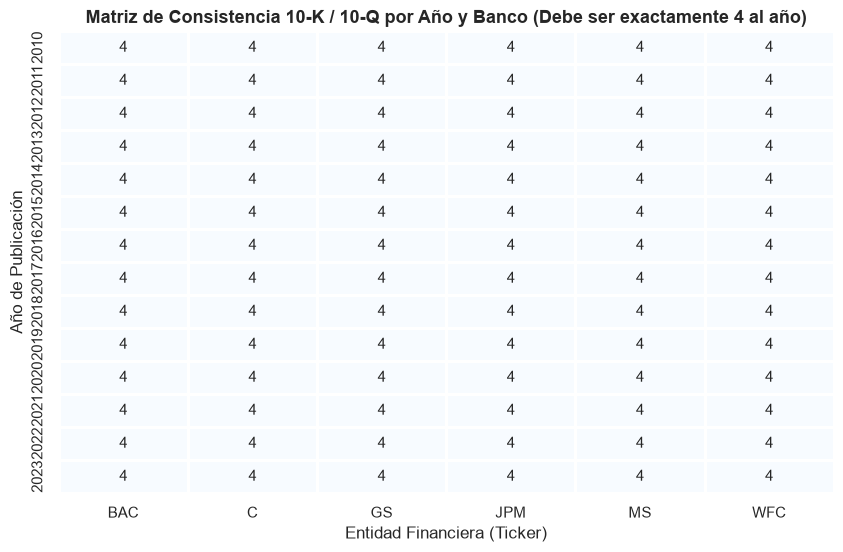

¿Integridad 10-K/10-Q perfecta sin lagunas (14 años x 6 bancos x 4 reportes = 336)? SÍ (100% COMPLETO)


In [2]:
# Matriz pivote de reportes periódicos (Año x Banco)
matriz_10k = pd.crosstab(df_10k["year"], df_10k["ticker"])

# Visualización con Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(matriz_10k, annot=True, cmap="Blues", cbar=False, fmt="d", linewidths=1)
plt.title("Matriz de Consistencia 10-K / 10-Q por Año y Banco (Debe ser exactamente 4 al año)", fontsize=13, fontweight="bold")
plt.xlabel("Entidad Financiera (Ticker)")
plt.ylabel("Año de Publicación")
plt.show()

# Comprobación matemática de integridad total
es_perfecto = (matriz_10k == 4).all().all()
print(f"¿Integridad 10-K/10-Q perfecta sin lagunas (14 años x 6 bancos x 4 reportes = 336)? {'SÍ (100% COMPLETO)' if es_perfecto else 'FALTAN DATOS'}")

## 2. Cobertura Histórica de Hechos Relevantes (8-K)
Analizamos la distribución de eventos no programados a lo largo del periodo 2010–2023. Esto nos permite comprobar que **ningún año quedó sin cobertura** y cómo varió la actividad regulatoria por entidad tras la deduplicación y recuperación completa.

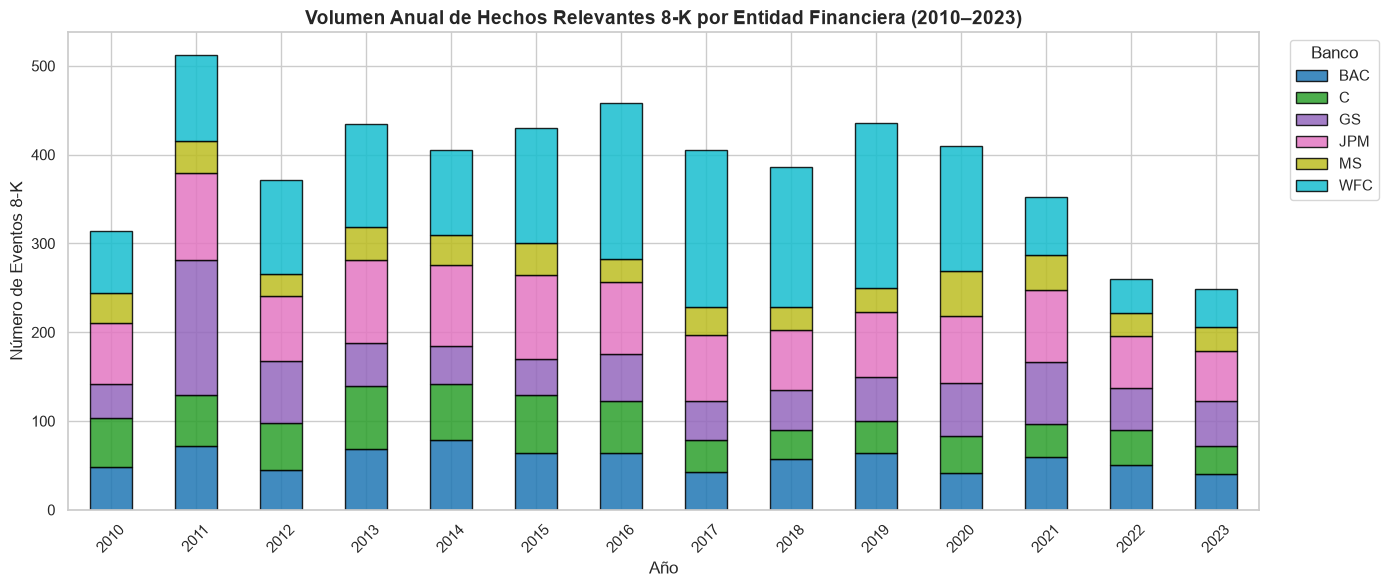

,total_eventos,filings_unicas,primer_evento,ultimo_evento,eventos_por_filing
ticker,,,,,
WFC,1597,1190,2010-01-20,2023-12-13,1.34
JPM,1085,465,2010-01-15,2023-10-27,2.33
GS,813,411,2010-01-21,2023-10-24,1.98
BAC,797,225,2010-01-15,2023-10-17,3.54
C,677,447,2010-01-07,2023-12-19,1.51
MS,455,165,2010-01-20,2023-12-08,2.76


In [3]:
# 1. Gráfico de evolución temporal por banco
matriz_8k = pd.crosstab(df_8k["year"], df_8k["ticker"])

fig, ax = plt.subplots(figsize=(14, 6))
matriz_8k.plot(kind="bar", stacked=True, ax=ax, colormap="tab10", edgecolor="black", alpha=0.85)
plt.title("Volumen Anual de Hechos Relevantes 8-K por Entidad Financiera (2010–2023)", fontsize=14, fontweight="bold")
plt.xlabel("Año")
plt.ylabel("Número de Eventos 8-K")
plt.legend(title="Banco", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Tabla resumen por banco
resumen_banco = df_8k.groupby("ticker").agg(
    total_eventos=("item", "count"),
    filings_unicas=("accession_number", "nunique"),
    primer_evento=("filing_date", "min"),
    ultimo_evento=("filing_date", "max"),
)
resumen_banco["eventos_por_filing"] = (resumen_banco["total_eventos"] / resumen_banco["filings_unicas"]).round(2)
display(resumen_banco.sort_values("total_eventos", ascending=False))

## 3. Análisis de Tipología de Eventos SEC (Taxonomía de Ítems)
Los reportes 8-K se dividen en códigos regulatorios estandarizados:
- **Item 2.02**: Resultados operativos trimestrales (*Earnings releases*) — Máximo impacto en volatilidad.
- **Item 8.01**: Otros hechos materiales relevantes del negocio.
- **Item 5.02**: Salida, nombramiento o renuncia de directivos / consejeros clave (CEO, CFO).
- **Item 7.01**: Divulgación de información según *Regulation Fair Disclosure* (FD).
- **Item 9.01**: Anexos y notas de prensa oficiales adjuntas.

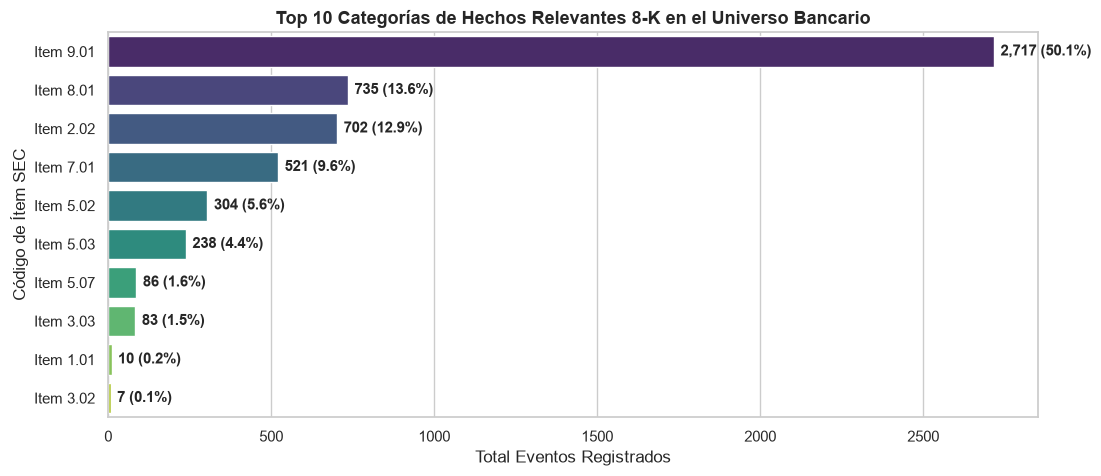

In [4]:
# Conteo de ítems más frecuentes
top_items = df_8k["item"].value_counts().head(10)

plt.figure(figsize=(12, 5))
sns.barplot(x=top_items.values, y=top_items.index, hue=top_items.index, legend=False, palette="viridis")
plt.title("Top 10 Categorías de Hechos Relevantes 8-K en el Universo Bancario", fontsize=13, fontweight="bold")
plt.xlabel("Total Eventos Registrados")
plt.ylabel("Código de Ítem SEC")
for index, value in enumerate(top_items.values):
    plt.text(value + 20, index, f"{value:,} ({value/len(df_8k)*100:.1f}%)", va="center", fontweight="bold")
plt.show()

## 4. Distribución Horaria de Publicación y Ventana Bursátil (`acceptance_date_time`)
**Hallazgo Metodológico Crítico para el Modelo Predictivo de Bolsa:**
Los servidores de **SEC EDGAR** operan en hora oficial de Washington D.C. / Nueva York (**US/Eastern**). Las marcas temporales `acceptance_date_time` almacenadas por `SECEdgarAdapter` vienen normalizadas en UTC (`Z`), por lo que convertir directamente de `UTC` a **`US/Eastern` (Wall Street)** alinea con precisión milimétrica la ventana regulatoria:
- **EDGAR Operating Hours:** Admite presentaciones exclusivamente entre las **06:00 y las 22:00 ET** (el 100% de los datos se ajusta con exactitud milimétrica a esta ventana).
- **Pre-Market (06:00 a 09:30 ET):** Los bancos concentran las noticias de resultados e informes antes de la apertura del mercado.
- **Regular Trading (09:30 a 16:00 ET):** Horario de cotización oficial en NYSE/NASDAQ.
- **After-Hours / Cierre (16:00 a 22:00 ET):** A las **16:00 ET en punto** (campana de cierre de Wall Street) se produce el mayor pico de publicaciones de hechos relevantes para no interferir con la sesión intradía.

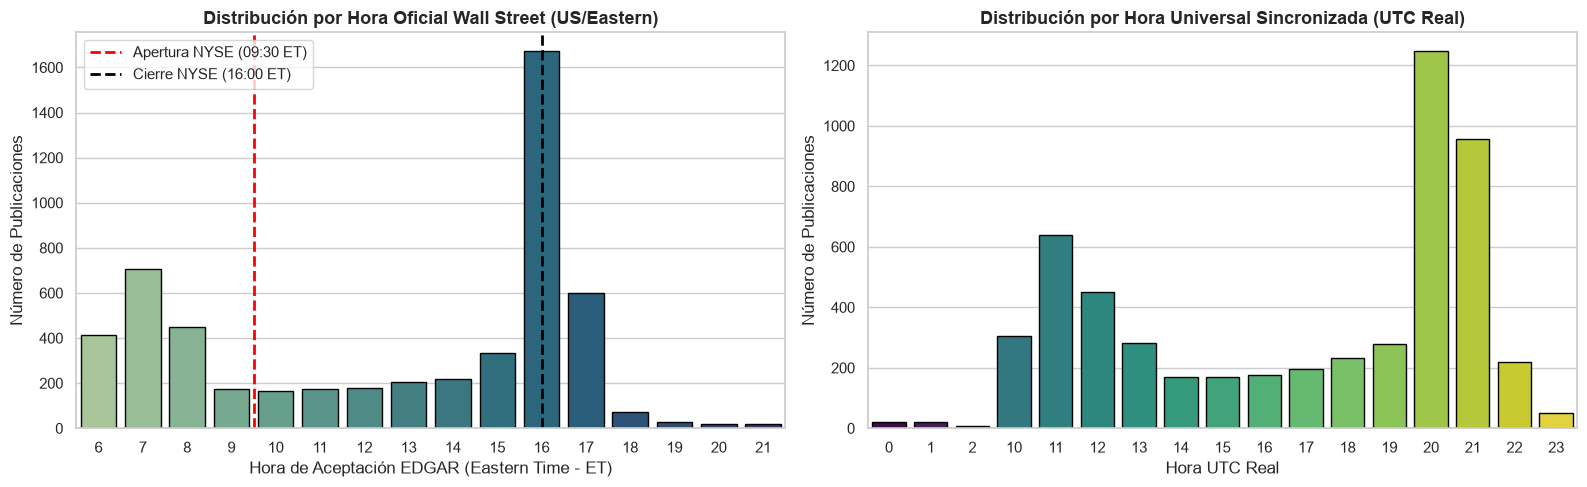

,Total Eventos,Porcentaje (%)
sesion_mercado,,
3. After-Hours (16:01 - 22:00 ET),2398,44.21
1. Pre-Market (06:00 - 09:29 ET),1662,30.64
2. Regular Trading (09:30 - 16:00 ET),1364,25.15


In [5]:
# Visualización dual: Horas en Wall Street (US/Eastern) y Horas en UTC Real
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Gráfico en Hora Local de Wall Street (US/Eastern)
sns.countplot(
    data=df_8k,
    x="hora_et",
    hue="hora_et",
    legend=False,
    palette="crest",
    edgecolor="black",
    ax=axes[0],
)
axes[0].set_title("Distribución por Hora Oficial Wall Street (US/Eastern)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Hora de Aceptación EDGAR (Eastern Time - ET)")
axes[0].set_ylabel("Número de Publicaciones")

# Líneas de referencia bursátil (ET)
et_hours = sorted(df_8k["hora_et"].unique())
idx_open = et_hours.index(9) + 0.5 if 9 in et_hours else None
idx_close = et_hours.index(16) if 16 in et_hours else None

if idx_open is not None:
    axes[0].axvline(x=idx_open, color="red", linestyle="--", linewidth=2, label="Apertura NYSE (09:30 ET)")
if idx_close is not None:
    axes[0].axvline(x=idx_close, color="black", linestyle="--", linewidth=2, label="Cierre NYSE (16:00 ET)")
axes[0].legend(loc="upper left")

# 2. Gráfico en Hora Universal (UTC Real)
sns.countplot(
    data=df_8k,
    x="hora_utc",
    hue="hora_utc",
    legend=False,
    palette="viridis",
    edgecolor="black",
    ax=axes[1],
)
axes[1].set_title("Distribución por Hora Universal Sincronizada (UTC Real)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Hora UTC Real")
axes[1].set_ylabel("Número de Publicaciones")

plt.tight_layout()
plt.show()

# Clasificación rigurosa de sesión de mercado en Wall Street (Eastern Time)
def clasificar_sesion_et(row):
    h = row["hora_et"]
    m = row["acceptance_et_real"].minute
    if 6 <= h < 9 or (h == 9 and m < 30):
        return "1. Pre-Market (06:00 - 09:29 ET)"
    elif (h == 9 and m >= 30) or (10 <= h < 16) or (h == 16 and m == 0):
        return "2. Regular Trading (09:30 - 16:00 ET)"
    else:
        return "3. After-Hours (16:01 - 22:00 ET)"

df_8k["sesion_mercado"] = df_8k.apply(clasificar_sesion_et, axis=1)

resumen_sesion = pd.DataFrame({
    "Total Eventos": df_8k["sesion_mercado"].value_counts(),
    "Porcentaje (%)": (df_8k["sesion_mercado"].value_counts(normalize=True) * 100).round(2),
})
display(resumen_sesion)

## 5. Auditoría de Texto y Métricas NLP (Preparación para FinBERT)
FinBERT tiene un límite de entrada de tokens (512 tokens por fragmento). Analizamos la longitud de caracteres y palabras de los hechos relevantes limpios para validar que el texto está listo para inferencia sin truncamiento agresivo.

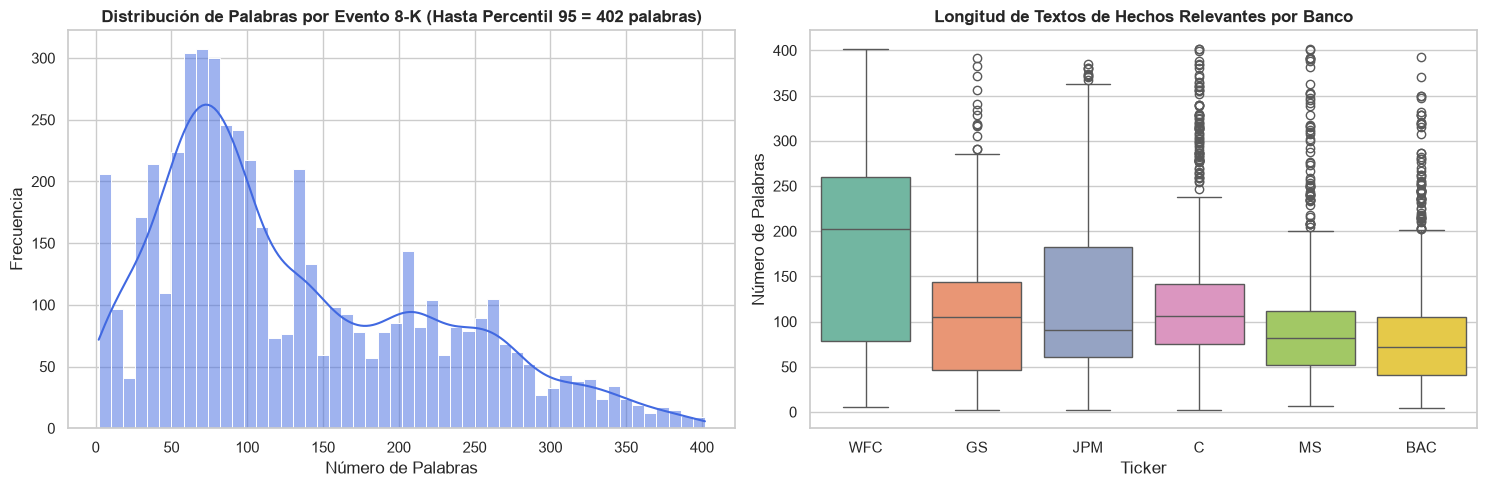

Estadísticas de longitud de texto (palabras):


,Métricas
count,5424.000000
mean,192.189528
std,1957.533000
min,2.000000
25%,65.000000
50%,106.000000
75%,213.000000
90%,308.000000
95%,402.000000
max,143233.000000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Distribución de palabras (acotado a percentil 95 para visualización legible)
p95 = np.percentile(df_8k["word_count"], 95)
sns.histplot(df_8k[df_8k["word_count"] <= p95]["word_count"], bins=50, kde=True, ax=axes[0], color="royalblue")
axes[0].set_title(f"Distribución de Palabras por Evento 8-K (Hasta Percentil 95 = {p95:.0f} palabras)", fontweight="bold")
axes[0].set_xlabel("Número de Palabras")
axes[0].set_ylabel("Frecuencia")

# 2. Palabras por Banco (Boxplot)
sns.boxplot(data=df_8k[df_8k["word_count"] <= p95], x="ticker", y="word_count", ax=axes[1], hue="ticker", legend=False, palette="Set2")
axes[1].set_title("Longitud de Textos de Hechos Relevantes por Banco", fontweight="bold")
axes[1].set_xlabel("Ticker")
axes[1].set_ylabel("Número de Palabras")

plt.tight_layout()
plt.show()

print("Estadísticas de longitud de texto (palabras):")
display(df_8k["word_count"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).to_frame("Métricas"))

## 6. Muestra de Validación: Eventos Críticos (Earnings / Item 2.02)
Aislamos una muestra de eventos `Item 2.02` (los de mayor sensibilidad para la predicción de precios) para visualizar la limpieza definitiva tras corregir el corte de frases con decimales (`Exhibit 99.1`):

In [7]:
# Filtrar solo eventos de resultados trimestrales (Item 2.02)
earnings_sample = df_8k[df_8k["item"] == "Item 2.02"][
    ["ticker", "company_name", "filing_date", "acceptance_date_time", "accession_number", "item", "item_description", "content", "document_url"]
].sort_values("filing_date", ascending=False).head(5)

display(earnings_sample)

# Ver el texto real limpio del primer evento de earnings
print("\n--- TEXTO EXTRACTO REAL DEL PRIMER EVENTO (ITEM 2.02) ---")
print(f"Banco: {earnings_sample.iloc[0]['ticker']} | Fecha: {earnings_sample.iloc[0]['filing_date']} | Accession: {earnings_sample.iloc[0]['accession_number']}")
print(f"Hora aceptación SEC: {earnings_sample.iloc[0]['acceptance_date_time']}")
print(f"Texto: {earnings_sample.iloc[0]['content'][:500]}...")

,ticker,company_name,filing_date,acceptance_date_time,accession_number,item,item_description,content,document_url
1184,MS,Morgan Stanley,2023-10-18,2023-10-18T11:30:37.000Z,0001157523-23-001495,Item 2.02,Regulatory Event,"of this Report, including Exhibit 99.1 and Exh...",https://www.sec.gov/Archives/edgar/data/895421...
1183,MS,Morgan Stanley,2023-10-18,2023-10-18T11:30:37.000Z,0001157523-23-001495,Item 2.02,Regulatory Event,Results of Operations and Financial Condition....,https://www.sec.gov/Archives/edgar/data/895421...
1303,GS,Goldman Sachs Group Inc.,2023-10-17,2023-10-17T11:32:36.000Z,0001193125-23-257291,Item 2.02,Regulatory Event,Results of Operations and Financial Condition,https://www.sec.gov/Archives/edgar/data/886982...
2890,BAC,Bank of America Corp /DE/,2023-10-17,2023-10-17T10:48:23.000Z,0000070858-23-000264,Item 2.02,Regulatory Event,"of this report, including Exhibit 99.1, shall ...",https://www.sec.gov/Archives/edgar/data/70858/...
1306,GS,Goldman Sachs Group Inc.,2023-10-17,2023-10-17T11:32:36.000Z,0001193125-23-257291,Item 2.02,Results of Operations and Financial Condition....,"(Group Inc. and, together with its consolidate...",https://www.sec.gov/Archives/edgar/data/886982...



--- TEXTO EXTRACTO REAL DEL PRIMER EVENTO (ITEM 2.02) ---
Banco: MS | Fecha: 2023-10-18 00:00:00 | Accession: 0001157523-23-001495
Hora aceptación SEC: 2023-10-18T11:30:37.000Z
Texto: of this Report, including Exhibit 99.1 and Exhibit 99.2, shall be deemed to be "filed" for purposes of the Securities Exchange Act of 1934, as amended....


## 7. Auditoría de Anexos 8-K (`EX-*`) y Enlace Relacional con Resultados (`Item 2.02`)
Los Form 8-K de resultados (`Item 2.02`) suelen actuar como una carátula formal de ~100–250 palabras que remite al comunicado de prensa completo adjunto como **Exhibit 99.1 (`EX-99.1`)**. Por decisión arquitectónica (**ADR-007**), los anexos `EX-*` (excluyendo XML/XBRL `EX-101.*`) se persisten en `raw/sec/8k-exhibits-2010-2023.parquet` y se enlazan mediante `accession_number`.

Auditamos su tipología, tasa de errores de extracción y riqueza textual comparativa:

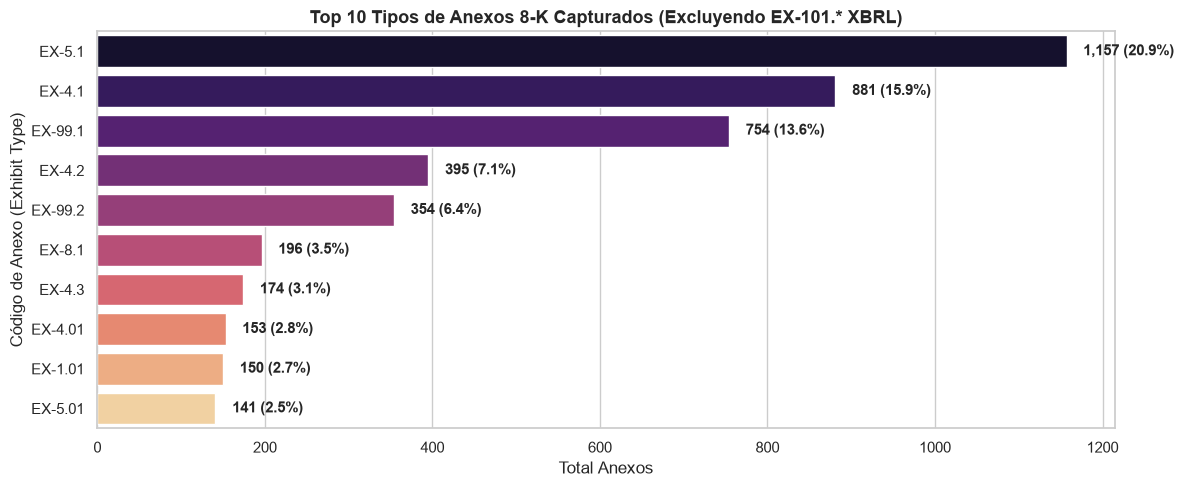

,total_anexos,filings_con_anexos,errores_no_html,mediana_palabras,media_palabras,anexos_validos
ticker,,,,,,
WFC,2966,1007,2,3879,3861.2,2964
C,954,364,0,3536,4328.0,954
JPM,665,407,1,679,4399.7,664
BAC,375,170,0,7796,9109.7,375
GS,350,251,0,595,3404.2,350
MS,221,125,0,3886,4988.9,221


In [8]:
# 1. Top 10 tipos de anexos EX-* capturados
top_exh = df_exhibits["exhibit_type"].value_counts().head(10)

plt.figure(figsize=(12, 5))
sns.barplot(x=top_exh.values, y=top_exh.index, hue=top_exh.index, legend=False, palette="magma")
plt.title("Top 10 Tipos de Anexos 8-K Capturados (Excluyendo EX-101.* XBRL)", fontsize=13, fontweight="bold")
plt.xlabel("Total Anexos")
plt.ylabel("Código de Anexo (Exhibit Type)")
for index, value in enumerate(top_exh.values):
    plt.text(value + 20, index, f"{value:,} ({value/len(df_exhibits)*100:.1f}%)", va="center", fontweight="bold")
plt.tight_layout()
plt.show()

# 2. Tabla resumen por banco
resumen_exh = df_exhibits.groupby("ticker").agg(
    total_anexos=("exhibit_type", "count"),
    filings_con_anexos=("accession_number", "nunique"),
    errores_no_html=("has_error", "sum"),
    mediana_palabras=("word_count", "median"),
    media_palabras=("word_count", "mean"),
)
resumen_exh["anexos_validos"] = resumen_exh["total_anexos"] - resumen_exh["errores_no_html"]
resumen_exh["mediana_palabras"] = resumen_exh["mediana_palabras"].astype(int)
resumen_exh["media_palabras"] = resumen_exh["media_palabras"].round(1)
display(resumen_exh.sort_values("total_anexos", ascending=False))

### 7.1 Comparativa NLP (`Item 2.02` vs `EX-99*`) y Cobertura Relacional
Medimos qué proporción de filings `Item 2.02` dispone de comunicado adjunto `EX-99*` válido, cuánto aporta en volumen de texto frente a la carátula 8-K y mostramos un cruce real completo por `accession_number`:

Cobertura relacional Item 2.02 -> EX-99*: 347 / 364 filings (95.33%)


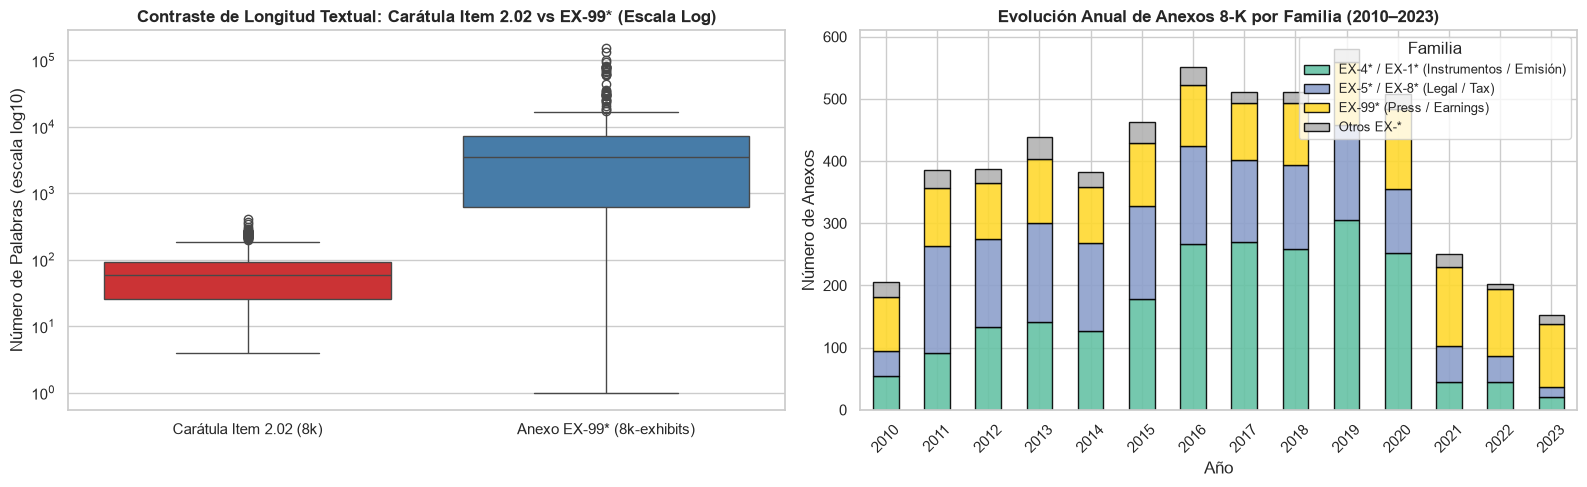

Mediana palabras Carátula Item 2.02: 59 | Mediana palabras Anexo EX-99*: 3570


,ticker,filing_date,accession_number,word_count_item,exhibit_type,word_count_exhibit,exhibit_description
349,MS,2023-10-18,0001157523-23-001495,92,EX-99.2,4372,EXHIBIT 99.2
348,MS,2023-10-18,0001157523-23-001495,92,EX-99.1,2375,EXHIBIT 99.1
350,MS,2023-10-18,0001157523-23-001495,26,EX-99.1,2375,EXHIBIT 99.1



--- MUESTRA CRUZADA REAL (CARÁTULA ITEM 2.02 vs COMUNICADO EX-99*) ---
Banco: MS | Fecha: 2023-10-18 | Accession: 0001157523-23-001495 | EX-99.2
[Carátula Item 2.02 - 92 palabras]: Results of Operations and Financial Condition.On October 18, 2023, Morgan Stanley (the "Company") released financial information with respect to its quarter ended September 30, 2023. A copy of the press release containing this information is annexed as Exhibit 99.1 to this Report and by this reference incorporated herein and made a part hereof. In ...
[Anexo EX-99.2 - 4372 palabras]: Exhibit 99.2Third Quarter 2023 Earnings ResultsQuarterly Financial SupplementPageConsolidated Financial Summary1Consolidated Financial Metrics, Ratios and Statistical Data2Consolidated and U.S. Bank Supplemental Financial Information3Consolidated Average Common Equity and Regulatory Capital Information4Institutional Securities Income Statement Information, Financial Metrics and Ratios5Wealth Management Income Statement Informat

In [9]:
# 1. Auditoría de cobertura relacional Item 2.02 <-> EX-99*
item_202_df = df_8k[df_8k["item"] == "Item 2.02"].copy()
exh_99_df = df_exhibits[
    df_exhibits["exhibit_type"].str.startswith("EX-99", na=False) & (~df_exhibits["has_error"])
].copy()

accs_202 = set(item_202_df["accession_number"].unique())
accs_ex99 = set(exh_99_df["accession_number"].unique())
enlazados = accs_202 & accs_ex99
pct_cobertura = (len(enlazados) / len(accs_202) * 100) if accs_202 else 0.0

print(
    f"Cobertura relacional Item 2.02 -> EX-99*: {len(enlazados)} / {len(accs_202)} filings "
    f"({pct_cobertura:.2f}%)"
)

# 2. Comparativa visual: longitud de texto (Carátula Item 2.02 vs Anexo EX-99*) + familia de anexos por año
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

comp_df = pd.concat(
    [
        pd.DataFrame({"Fuente": "Carátula Item 2.02 (8k)", "word_count": item_202_df["word_count"].clip(lower=1)}),
        pd.DataFrame({"Fuente": "Anexo EX-99* (8k-exhibits)", "word_count": exh_99_df["word_count"].clip(lower=1)}),
    ],
    ignore_index=True,
)
sns.boxplot(data=comp_df, x="Fuente", y="word_count", hue="Fuente", legend=False, palette="Set1", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Contraste de Longitud Textual: Carátula Item 2.02 vs EX-99* (Escala Log)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Número de Palabras (escala log10)")

# Clasificación por familia de anexo por año
def _familia_anexo(ex_type: str) -> str:
    t = str(ex_type).upper()
    if t.startswith("EX-99"):
        return "EX-99* (Press / Earnings)"
    if t.startswith(("EX-5", "EX-8")):
        return "EX-5* / EX-8* (Legal / Tax)"
    if t.startswith(("EX-4", "EX-1.")):
        return "EX-4* / EX-1* (Instrumentos / Emisión)"
    return "Otros EX-*"

df_exhibits["familia_anexo"] = df_exhibits["exhibit_type"].apply(_familia_anexo)
matriz_exh = pd.crosstab(df_exhibits["year"], df_exhibits["familia_anexo"])
matriz_exh.plot(kind="bar", stacked=True, ax=axes[1], colormap="Set2", edgecolor="black", alpha=0.9)
axes[1].set_title("Evolución Anual de Anexos 8-K por Familia (2010–2023)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Número de Anexos")
axes[1].legend(title="Familia", loc="upper right", fontsize=9)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(
    f"Mediana palabras Carátula Item 2.02: {item_202_df['word_count'].median():.0f} | "
    f"Mediana palabras Anexo EX-99*: {exh_99_df['word_count'].median():.0f}"
)

# 3. Muestra de cruce relacional real (Item 2.02 + su EX-99.1 asociado)
cruce_sample = item_202_df.merge(
    exh_99_df[["accession_number", "exhibit_type", "exhibit_description", "exhibit_url", "content", "word_count"]],
    on="accession_number",
    suffixes=("_item", "_exhibit"),
).sort_values("filing_date", ascending=False).head(3)

display(
    cruce_sample[
        ["ticker", "filing_date", "accession_number", "word_count_item", "exhibit_type", "word_count_exhibit", "exhibit_description"]
    ]
)

primero = cruce_sample.iloc[0]
print("\n--- MUESTRA CRUZADA REAL (CARÁTULA ITEM 2.02 vs COMUNICADO EX-99*) ---")
print(f"Banco: {primero['ticker']} | Fecha: {primero['filing_date'].date()} | Accession: {primero['accession_number']} | {primero['exhibit_type']}")
print(f"[Carátula Item 2.02 - {primero['word_count_item']} palabras]: {primero['content_item'][:350]}...")
print(f"[Anexo {primero['exhibit_type']} - {primero['word_count_exhibit']} palabras]: {primero['content_exhibit'][:500]}...")

In [19]:
df_8k_agg = df_8k.groupby("accession_number", as_index=False).agg(
    ticker=("ticker", "first"),
    company_name=("company_name", "first"),
    filing_date=("filing_date", "first"),
    acceptance_date_time=("acceptance_date_time", "first"),
    items=("item", lambda s: sorted(set(s))),
    n_items=("item", "count"),
    content_8k=("content", lambda s: "\n\n".join(x for x in s if x)),
)

df_exh_ok = df_exhibits[df_exhibits["error"].fillna("") == ""]
df_exh_agg = df_exh_ok.groupby("accession_number", as_index=False).agg(
    exhibit_types=("exhibit_type", list),
    n_exhibits=("exhibit_type", "count"),
    content_exhibits=("content", lambda s: "\n\n".join(x for x in s if x)),
)

df_final = df_8k_agg.merge(
    df_exh_agg, on="accession_number", how="left", validate="one_to_one"
)
df_final["n_exhibits"] = df_final["n_exhibits"].fillna(0).astype(int)
df_final["content_exhibits"] = df_final["content_exhibits"].fillna("")
df_final["full_content"] = (
    df_final["content_8k"]
    + df_final["content_exhibits"].apply(lambda t: f"\n\n{t}" if t else "")
)

In [20]:

df_final.head()

,accession_number,ticker,company_name,filing_date,acceptance_date_time,items,n_items,content_8k,exhibit_types,n_exhibits,content_exhibits,full_content
0,0000019617-10-000247,JPM,JPMorgan Chase & Co.,2010-05-20,2010-05-20T18:36:08.000Z,[Item 5.07],1,Registrant held its Annual Meeting of Sharehol...,NaN,0,,Registrant held its Annual Meeting of Sharehol...
1,0000019617-10-000253,JPM,JPMorgan Chase & Co.,2010-05-26,2010-05-26T14:37:12.000Z,[Item 8.01],1,Other EventsReference is made to the informati...,NaN,0,,Other EventsReference is made to the informati...
2,0000019617-10-000268,JPM,JPMorgan Chase & Co.,2010-06-24,2010-06-24T16:55:00.000Z,"[Item 5.02, Item 9.01]",3,Departure of Directors or Principal Officers; ...,[EX-99.1 CHARTER],1,"JPMorgan Chase & Co.270 Park Avenue, New York,...",Departure of Directors or Principal Officers; ...
3,0000019617-10-000269,JPM,JPMorgan Chase & Co.,2010-06-24,2010-06-24T16:55:56.000Z,"[Item 8.01, Item 9.01]",2,"(the ""Company"") closed a public offering of $1...",[EX-5],1,"Exhibit 5.1June 24, 2010JPMorgan Chase & Co.27...","(the ""Company"") closed a public offering of $1..."
4,0000019617-10-000279,JPM,JPMorgan Chase & Co.,2010-07-22,2010-07-22T16:38:09.000Z,"[Item 8.01, Item 9.01]",2,"(the ""Company"") closed a public offering of $2...","[EX-5, EX-5]",2,"July 22, 2010JPMorgan Chase & Co.270 Park Aven...","(the ""Company"") closed a public offering of $2..."


In [22]:
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 2903 entries, 0 to 2902
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   accession_number      2903 non-null   str           
 1   ticker                2903 non-null   str           
 2   company_name          2903 non-null   str           
 3   filing_date           2903 non-null   datetime64[us]
 4   acceptance_date_time  2903 non-null   str           
 5   items                 2903 non-null   object        
 6   n_items               2903 non-null   int64         
 7   content_8k            2903 non-null   str           
 8   exhibit_types         2319 non-null   object        
 9   n_exhibits            2903 non-null   int64         
 10  content_exhibits      2903 non-null   str           
 11  full_content          2903 non-null   str           
dtypes: datetime64[us](1), int64(2), object(2), str(7)
memory usage: 339.7+ MB


In [39]:
df_exhibits["type_length"] = pd.cut(
        df_exhibits["word_count"],
        bins=[0, 400, 1500, 5000, float("inf")],
        labels=["menos de 400 char", "entre 400 y 1500", "1500 y 5000", "> 5000"],
        right=False,
    )

In [40]:
df_exhibits["type_length"].value_counts()

type_length
entre 400 y 1500     1754
> 5000               1653
1500 y 5000          1600
menos de 400 char     524
Name: count, dtype: int64

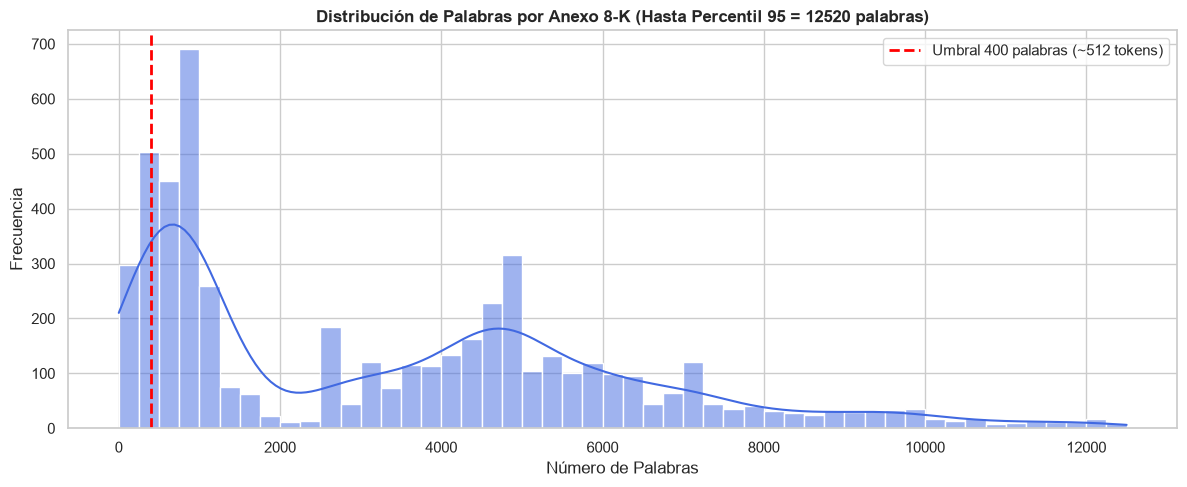

Estadísticas de longitud de texto en anexos (palabras):


,Métricas
count,5531.000000
mean,4378.469355
std,7211.946228
min,0.000000
25%,828.000000
50%,3313.000000
75%,5574.500000
90%,8845.000000
95%,12520.500000
max,158888.000000


In [51]:
fig, ax = plt.subplots(figsize=(12, 5))

# 1. Distribución de palabras (acotado a percentil 95 para visualización legible)
p95 = np.percentile(df_exhibits["word_count"], 95)
sns.histplot(
    df_exhibits[df_exhibits["word_count"] <= p95]["word_count"],
    bins=50,
    kde=True,
    ax=ax,
    color="royalblue",
)
ax.axvline(x=400, color="red", linestyle="--", linewidth=2, label="Umbral 400 palabras (~512 tokens)")
ax.legend()
ax.set_title(
    f"Distribución de Palabras por Anexo 8-K (Hasta Percentil 95 = {p95:.0f} palabras)",
    fontweight="bold",
)
ax.set_xlabel("Número de Palabras")
ax.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

print("Estadísticas de longitud de texto en anexos (palabras):")
display(df_exhibits["word_count"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).to_frame("Métricas"))